In [24]:
import numpy as np
import matplotlib.pyplot as plt

import importlib
import importfile
importlib.reload(importfile)
from importfile import *

P1 = np.array(
    [[0.5, 0.2, 0.3], 
    [0.025, 0.9125, 0.0625], 
    [0.3, 0.5, 0.2]]
)

P2 = np.array([
    [0.5, 0.2, 0.3],
    [0.025, 0.9125, 0.0625],
    [0.3, 0.5, 0.2],
])

transition_probs1 = [
    (0, 0, 0.3),
    (0, 1, 0.4),
    (0, 2, 0.3),
    (1, 0, 0.05),
    (1, 1, 0.8875),
    (1, 2, 0.0625),
    (2, 0, 0.3),
    (2, 1, 0.5),
    (2, 2, 0.2),
]

transition_probs2 = [
    (0, 0, 0.5),
    (0, 1, 0.2),
    (0, 2, 0.3),
    (1, 0, 0.025),
    (1, 1, 0.9125),
    (1, 2, 0.0625),
    (2, 0, 0.3),
    (2, 1, 0.5),
    (2, 2, 0.2),
]

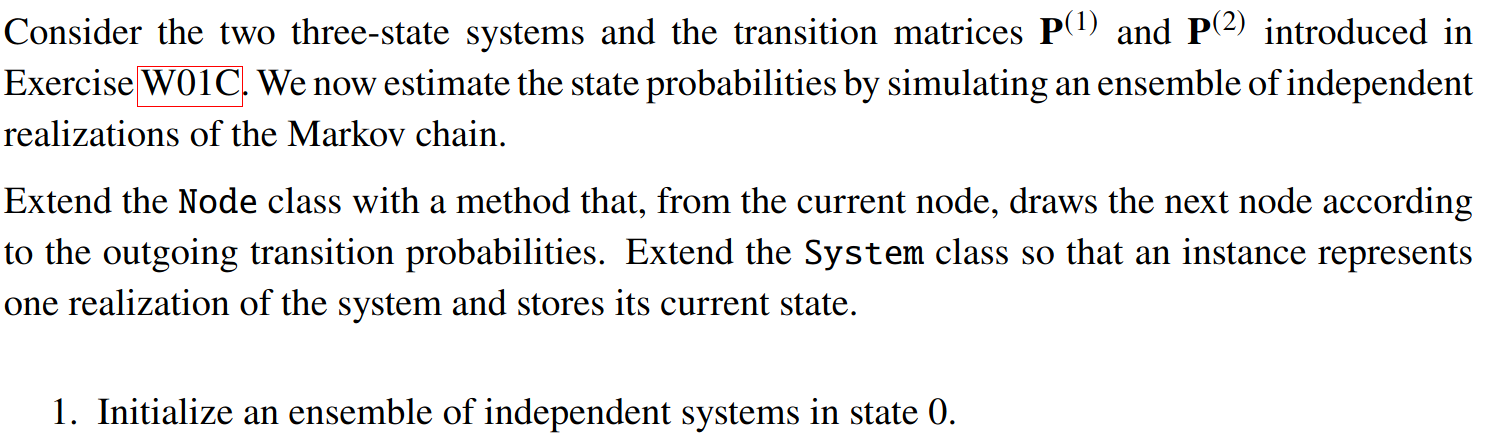

In [25]:
nodes = build_nodes(transition_probs1)
n = 1000 # systems
iterations = 10

ensembles = [System(nodes) for _ in range(n)]
print(all(s.state == 0 for s in ensembles))   # True

True


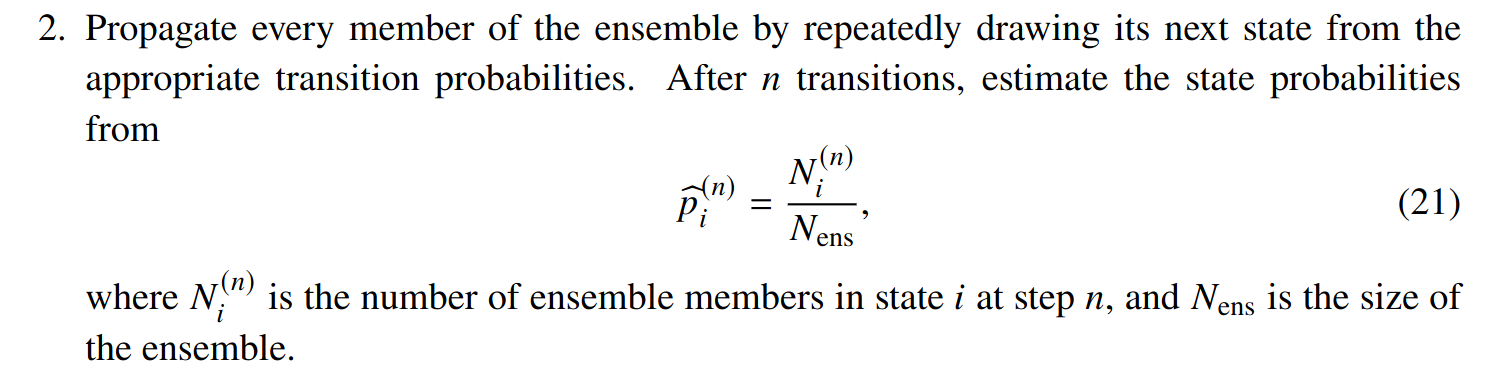

In [26]:
p_hat = np.zeros((n + 1, 3))
p_hat[0] = np.bincount([s.state for s in ensembles], minlength=3) / n

for t in range(1, n + 1):
    for s in ensembles:
        s.step()
    N_i = np.bincount([s.state for s in ensembles], minlength=3)
    p_hat[t] = N_i / n

print(p_hat[10])

ref = System(nodes, initial_state=0)
exact = [ref.prob_vector.copy()]
for _ in range(n):
    ref.propagate_pvector(1)
    exact.append(ref.prob_vector.copy())
exact = np.array(exact)

print(np.abs(p_hat - exact).max())

[0.103 0.797 0.1  ]
0.049000000000001154


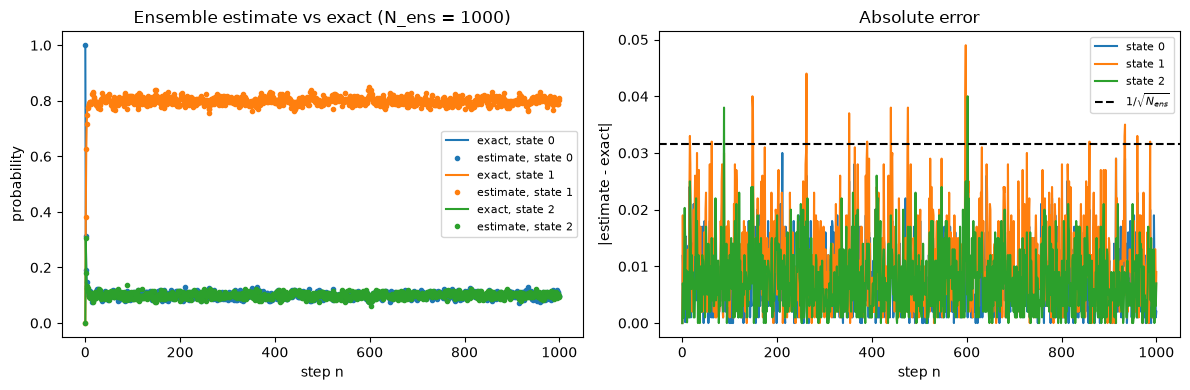

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# estimated vs exact probabilities
colors = ['C0', 'C1', 'C2']
for i in range(3):
    axes[0].plot(exact[:, i], '-', color=colors[i], label=f'exact, state {i}')
    axes[0].plot(p_hat[:, i], '.', color=colors[i], label=f'estimate, state {i}')
axes[0].set_xlabel('step n')
axes[0].set_ylabel('probability')
axes[0].set_title(f'Ensemble estimate vs exact (N_ens = {n})')
axes[0].legend(fontsize=8)

# absolute error over time
for i in range(3):
    axes[1].plot(np.abs(p_hat[:, i] - exact[:, i]), color=colors[i], label=f'state {i}')
axes[1].axhline(1 / np.sqrt(n), color='k', linestyle='--', label=r'$1/\sqrt{N_{ens}}$')
axes[1].set_xlabel('step n')
axes[1].set_ylabel('|estimate - exact|')
axes[1].set_title('Absolute error')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

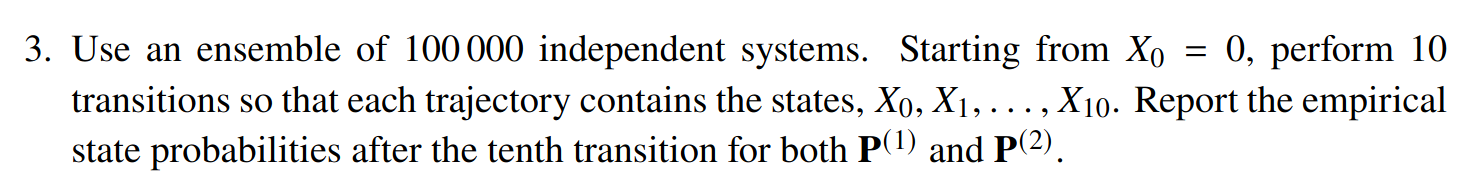

In [28]:
N_ens = 100_000
n_steps = 10

data = {}
for name, probs in [("P(1)", transition_probs1), ("P(2)", transition_probs2)]:
    nodes = build_nodes(probs)
    ensemble = [System(nodes, initial_state=0) for _ in range(N_ens)]
    for s in ensemble:
        s.simulate(n_steps)

    H = np.array([s.history for s in ensemble])          # shape (N_ens, 11)
    p_hat = np.array([np.bincount(H[:, t], minlength=3) / N_ens
                      for t in range(n_steps + 1)])      # shape (11, 3)

    ref = System(nodes, initial_state=0)
    exact = [ref.prob_vector.copy()]
    for _ in range(n_steps):
        ref.propagate_pvector(1)
        exact.append(ref.prob_vector.copy())
    exact = np.array(exact)

    data[name] = (p_hat, exact)

P(1): p0 = 0.1004, p1 = 0.7991, p2 = 0.1004, sum = 1.0000
P(2): p0 = 0.1041, p1 = 0.7935, p2 = 0.1024, sum = 1.0000


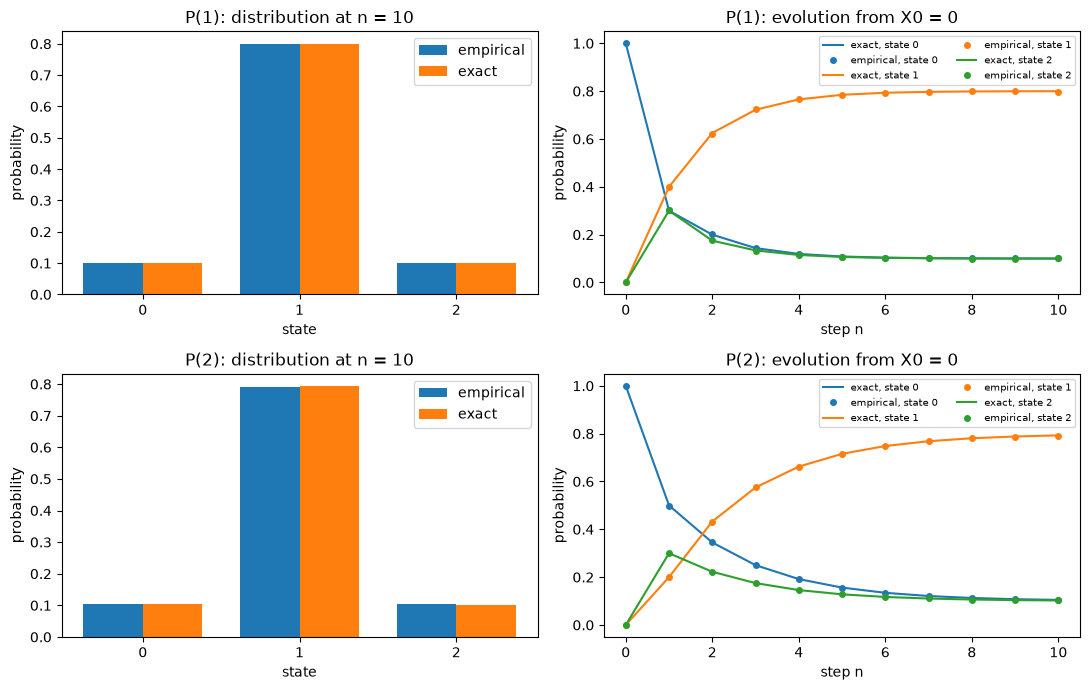

In [29]:
for name, p in results.items():
    print(f"{name}: p0 = {p[0]:.4f}, p1 = {p[1]:.4f}, p2 = {p[2]:.4f}, sum = {p.sum():.4f}")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
width = 0.38
states = np.arange(3)

for row, (name, (p_hat, exact)) in enumerate(data.items()):
    # left: distribution after the tenth transition
    ax = axes[row, 0]
    ax.bar(states - width/2, p_hat[-1], width, label='empirical')
    ax.bar(states + width/2, exact[-1], width, label='exact')
    ax.set_xticks(states)
    ax.set_xlabel('state')
    ax.set_ylabel('probability')
    ax.set_title(f'{name}: distribution at n = {n_steps}')
    ax.legend()

    # right: evolution over time
    ax = axes[row, 1]
    for i in range(3):
        ax.plot(exact[:, i], '-', color=f'C{i}', label=f'exact, state {i}')
        ax.plot(p_hat[:, i], 'o', color=f'C{i}', ms=4, label=f'empirical, state {i}')
    ax.set_xlabel('step n')
    ax.set_ylabel('probability')
    ax.set_title(f'{name}: evolution from X0 = 0')
    ax.legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

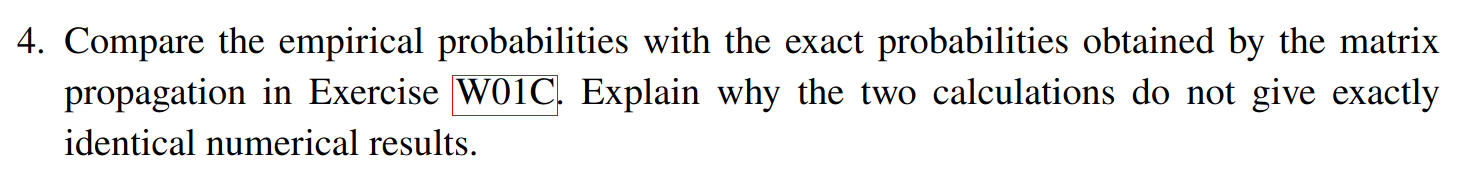

In [ ]:
# Results from previous exercise:
# [0.10014866 0.79973609 0.10011526]
# Result from current exercise
# [0.1004, 0.7991, 0.1004]

# The exact calculation is deterministic, while the empirical one is an estimate


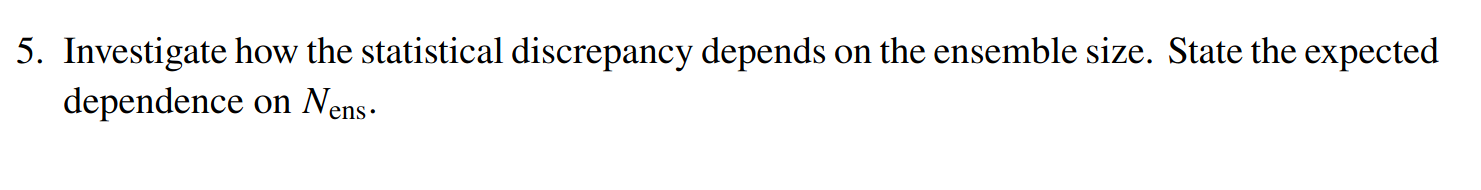

In [31]:
rng = np.random.default_rng(0)
system_P1 = System(build_nodes(transition_probs1)).Transition
system_P2 = System(build_nodes(transition_probs2)).Transition

def run_ensemble(P, N_ens, n_steps=10):
    """Propagate N_ens independent walkers; return empirical p^(n_steps)."""
    states = np.zeros(N_ens, dtype=int)
    cum = np.cumsum(P, axis=1)                    # row-wise cumulative probs
    for _ in range(n_steps):
        u = rng.random(N_ens)
        states = (u[:, None] > cum[states]).sum(axis=1)   # inverse-CDF draw
    return np.bincount(states, minlength=3) / N_ens

P_mats = {"P(1)": system_P1, "P(2)": system_P2}   # see note below
N_values = np.logspace(2, 6, 9).astype(int)       # 100 ... 1,000,000
n_repeats = 20

errors = {}
for name, P in P_mats.items():
    exact = np.linalg.matrix_power(P, 10)[0]      # row 0 = start in state 0
    errors[name] = []
    for N in N_values:
        diffs = [np.abs(run_ensemble(P, N) - exact).max() for _ in range(n_repeats)]
        errors[name].append(np.mean(diffs))



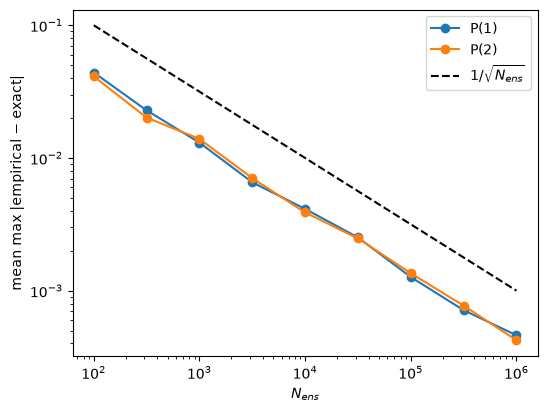

P(1) fitted slope: -0.496
P(2) fitted slope: -0.49


In [32]:
plt.figure(figsize=(6, 4.5))
for name in errors:
    plt.loglog(N_values, errors[name], 'o-', label=name)
plt.loglog(N_values, 1 / np.sqrt(N_values), 'k--', label=r'$1/\sqrt{N_{ens}}$')
plt.xlabel(r'$N_{ens}$')
plt.ylabel('mean max |empirical − exact|')
plt.legend()
plt.show()

# fitted slope
for name in errors:
    slope = np.polyfit(np.log(N_values), np.log(errors[name]), 1)[0]
    print(name, "fitted slope:", round(slope, 3))   # expect about -0.5